# Marca d'Água: EDA e pré-processamento para o modelo de risco

Global Solution 2026.2, FIAP, Machine Learning & Modelling.
Rafael Gonçalves (RM 569461) e Charles Augusto (RM 571908).

Este notebook cobre entendimento do problema, análise exploratória, construção do alvo e dos atributos, separação temporal em treino e teste e o pré-processamento. A modelagem vem em seguida: baselines, três modelos, tuning com validação temporal e avaliação no teste. Importância das variáveis, escolha do modelo final e aplicação fecham o notebook.

## 1. Entendimento do problema

**Problema.** O nó Marca d'Água mede nível da água e chuva em áreas de risco de Porto Alegre e avisa no local. O modelo de ML acrescenta uma previsão: a cada 6 horas, a chuva acumulada nas próximas 72 horas vai passar de um limiar? É uma classificação binária.

**Público.** Moradores de áreas sujeitas a alagamento que recebem o aviso do nó e, pela nuvem, as notificações da solução. Quem decide é o morador, então um alarme perdido custa mais que um alarme falso. Por isso a avaliação vai usar PR-AUC, recall e um limiar de decisão ajustado, e não só acurácia.

**Fonte.** Dados horários da estação automática A801 (Porto Alegre) do INMET, 2014 a 2025. São dados reais. O uso da base foi confirmado por escrito pelo professor de Redes Neurais (print em `docs/evidencias/`).

**Por que chuva acumulada e não o nível do Guaíba.** O plano original usava o nível do Guaíba acima da cota de inundação (HidroWeb/ANA). Em 06/11 os downloads da estação 87450004 vieram vazios e a 87450020 devolveu só vazão, então adotamos o plano B: o alvo sai da própria série de chuva do INMET. O alvo é uma aproximação do risco. Chuva alta em 72 h não garante alagamento, e esse limite fica registrado como limitação.

**Alvo.** `alvo = 1` se a soma da chuva em (t, t+72 h] for maior ou igual a `LIMIAR_MM`, e `0` caso contrário. O limiar é escolhido na seção 4 olhando só o período de treino.

**Variáveis de entrada** (todas calculadas só com o que já era conhecido no instante t):

| Grupo | Variáveis |
|---|---|
| Chuva acumulada para trás | 1, 3, 6, 12, 24, 48, 72 e 168 h |
| Pressão | valor atual e variação em 3 h e 24 h |
| Ar | temperatura, umidade, diferença temperatura menos ponto de orvalho |
| Vento | velocidade e rajada máxima |
| Estado de seca | horas desde a última chuva (limitado a 240 h) |
| Sazonalidade | seno e cosseno do dia do ano |

In [ ]:
import os, re, zipfile, unicodedata, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 42
ANOS = range(2014, 2026)
ESTACAO = "A801"
PASTA = "dados_inmet"
URL = "https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip"

JANELA_ALVO_H = 72
PASSO_AMOSTRA_H = 6
CORTE_TESTE = pd.Timestamp("2023-01-01")

## 2. Carga dos dados

O INMET publica um zip por ano com um CSV por estação. A célula baixa os zips para a pasta `dados_inmet/` (fora do Git). Se o portal recusar o download, baixe os zips à mão em portal.inmet.gov.br, aba Dados Históricos, e envie para essa pasta pelo painel de arquivos do Colab. A célula pula o que já existir.

In [ ]:
os.makedirs(PASTA, exist_ok=True)
falhas = []
for ano in ANOS:
    destino = f"{PASTA}/{ano}.zip"
    if os.path.exists(destino):
        continue
    try:
        req = urllib.request.Request(URL.format(ano=ano), headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=90) as r, open(destino, "wb") as f:
            f.write(r.read())
    except Exception as e:
        falhas.append((ano, str(e)[:70]))

presentes = [a for a in ANOS if os.path.exists(f"{PASTA}/{a}.zip")]
print("zips disponíveis:", presentes)
if falhas:
    print("falha no download:", falhas)
assert len(presentes) >= 8, "poucos anos carregados: baixe os zips à mão para dados_inmet/"

zips disponíveis: [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [ ]:
def sem_acento(s):
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().upper()

# o nome das colunas muda um pouco de ano para ano (acentos, parênteses), então casa por trecho
def nome_curto(col):
    c = sem_acento(col)
    if c.startswith("DATA"): return "data"
    if c.startswith("HORA"): return "hora"
    if "PRECIPITACAO" in c: return "chuva_mm"
    if "NIVEL DA ESTACAO" in c: return "pressao_mb"
    if "BULBO SECO" in c: return "temp_c"
    if "PONTO DE ORVALHO" in c and "MAX" not in c and "MIN" not in c: return "orvalho_c"
    if "UMIDADE RELATIVA DO AR" in c: return "umid_pct"
    if "VENTO, VELOCIDADE" in c: return "vento_ms"
    if "VENTO, RAJADA" in c: return "rajada_ms"
    return None

def le_ano(caminho):
    with zipfile.ZipFile(caminho) as z:
        nomes = [n for n in z.namelist() if f"_{ESTACAO}_" in n.upper()]
        if not nomes:
            raise FileNotFoundError(f"estação {ESTACAO} não está em {caminho}")
        with z.open(nomes[0]) as f:
            df = pd.read_csv(f, sep=";", skiprows=8, encoding="latin-1",
                             decimal=",", na_values=["-9999", "-9999,0"],
                             dtype={0: str, 1: str})  # hora "0100" viraria o numero 100
    df = df.rename(columns={c: nome_curto(c) for c in df.columns})
    df = df[[c for c in df.columns if c is not None and isinstance(c, str)]]
    df = df.loc[:, ~df.columns.duplicated()]
    # data aparece como 2014/01/01 ou 2014-01-01, hora como 0000 ou 0000 UTC (sempre UTC)
    d = df["data"].astype(str).str.replace("/", "-", regex=False)
    h = df["hora"].astype(str).str.extract(r"(\d{2})")[0]
    df["dt"] = pd.to_datetime(d + " " + h + ":00", errors="coerce")
    return df.drop(columns=["data", "hora"])

bruto = pd.concat([le_ano(f"{PASTA}/{a}.zip") for a in presentes], ignore_index=True)
print(bruto.shape)
bruto.head()

(105192, 8)


,chuva_mm,pressao_mb,temp_c,orvalho_c,umid_pct,rajada_ms,vento_ms,dt
0,0.0,1001.3,25.3,20.1,73.0,3.6,1.0,2014-01-01 00:00:00
1,0.0,1001.5,24.6,20.7,79.0,2.2,0.0,2014-01-01 01:00:00
2,0.0,1001.1,24.8,20.7,78.0,1.8,0.5,2014-01-01 02:00:00
3,0.0,1000.7,24.2,20.6,80.0,2.5,1.0,2014-01-01 03:00:00
4,0.0,1000.7,24.4,21.1,82.0,2.3,0.5,2014-01-01 04:00:00


## 3. Qualidade dos dados

Os registros do INMET trazem `-9999` onde o sensor falhou (tratado como ausente na leitura). A série precisa ser horária e regular, então reindexamos para uma linha por hora e deixamos as horas sem registro como ausentes. Valores fisicamente impossíveis viram ausentes.

In [ ]:
print("datas inválidas:", bruto["dt"].isna().sum())
print("registros duplicados no mesmo horário:", bruto["dt"].duplicated().sum())

bruto = bruto.dropna(subset=["dt"]).drop_duplicates("dt").set_index("dt").sort_index()
horario = bruto.reindex(pd.date_range(bruto.index.min(), bruto.index.max(), freq="h"))
horario.index.name = "dt"
print("horas esperadas:", len(horario), "| horas com registro:", len(bruto),
      "| horas ausentes na grade:", len(horario) - len(bruto))

limites = {"chuva_mm": (0, 150), "pressao_mb": (900, 1100), "temp_c": (-10, 50),
           "orvalho_c": (-20, 40), "umid_pct": (0, 100), "vento_ms": (0, 60), "rajada_ms": (0, 90)}
for col, (lo, hi) in limites.items():
    fora = ((horario[col] < lo) | (horario[col] > hi)).sum()
    if fora:
        print(f"{col}: {fora} valores fora de [{lo}, {hi}] viraram ausentes")
    horario.loc[(horario[col] < lo) | (horario[col] > hi), col] = np.nan

horario[list(limites)].describe().T.round(2)

datas inválidas: 0
registros duplicados no mesmo horário: 0
horas esperadas: 105192 | horas com registro: 105192 | horas ausentes na grade: 0


,count,mean,std,min,25%,50%,75%,max
chuva_mm,104654.0,0.19,1.16,0.0,0.0,0.0,0.0,47.6
pressao_mb,104654.0,1009.92,5.55,988.7,1006.0,1009.7,1013.6,1030.2
temp_c,104652.0,20.18,5.69,2.3,16.3,20.2,23.9,40.2
orvalho_c,104647.0,15.71,4.59,-3.4,12.8,16.2,19.2,27.1
umid_pct,104649.0,77.50,15.74,15.0,66.0,81.0,91.0,100.0
vento_ms,103000.0,1.45,0.89,0.0,0.8,1.3,2.0,7.9
rajada_ms,102954.0,4.71,2.55,0.0,2.7,4.4,6.3,33.2


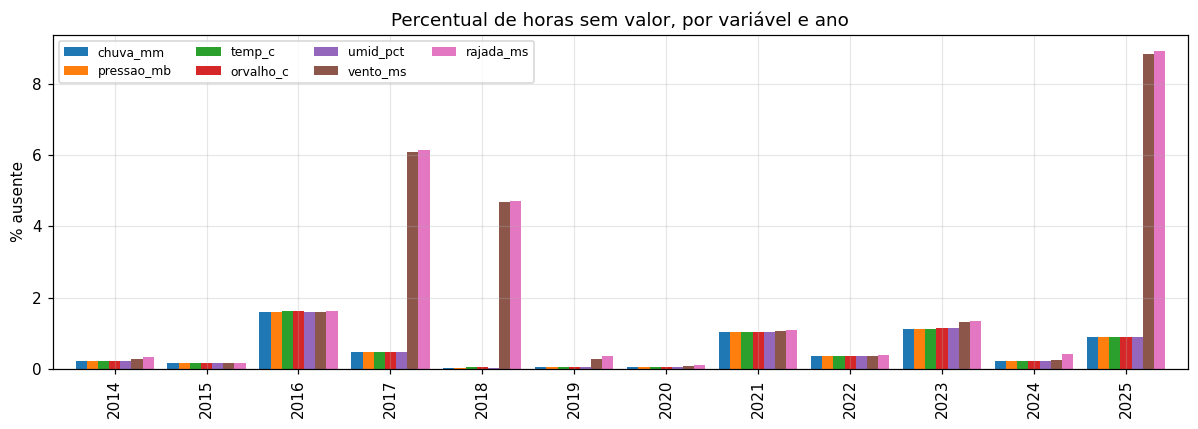

   63 h seguidas sem chuva registrada, começando em 2021-01-02 05:00:00
   39 h seguidas sem chuva registrada, começando em 2016-02-03 20:00:00
   34 h seguidas sem chuva registrada, começando em 2023-05-27 05:00:00
   26 h seguidas sem chuva registrada, começando em 2016-02-02 15:00:00
   20 h seguidas sem chuva registrada, começando em 2016-02-01 18:00:00


In [ ]:
faltas = horario[list(limites)].isna().groupby(horario.index.year).mean() * 100
ax = faltas.plot(kind="bar", figsize=(11, 4), width=0.85)
ax.set_title("Percentual de horas sem valor, por variável e ano")
ax.set_ylabel("% ausente"); ax.set_xlabel("")
ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

# maiores buracos seguidos na chuva
sem = horario["chuva_mm"].isna()
bloco = (sem != sem.shift()).cumsum()
buracos = sem.groupby(bloco).agg(["first", "size"])
buracos = buracos[buracos["first"]]["size"].sort_values(ascending=False).head(5)
for b, n in buracos.items():
    ini = sem[bloco == b].index[0]
    print(f"{n:>5} h seguidas sem chuva registrada, começando em {ini}")

## 4. Análise exploratória

Os gráficos desta seção usam a série inteira só para descrever o fenômeno. Nenhuma decisão de modelagem (limiar, imputação, escala) usa o período de teste.

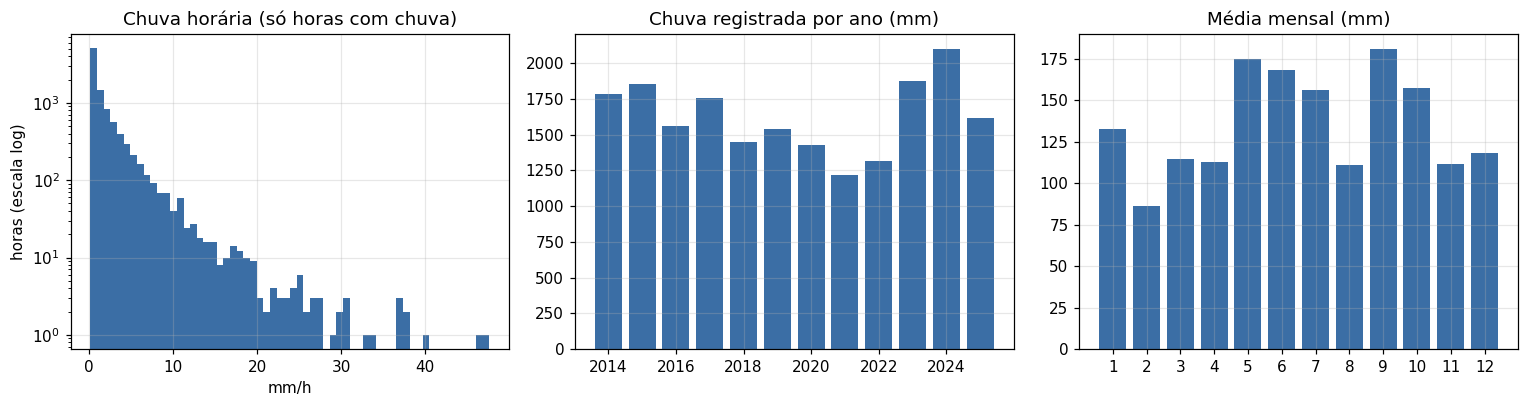

chuva horária máxima: 47.6 mm em 2022-01-26 21:00:00
horas com chuva > 0,1 mm: 9.2%


In [ ]:
chuva = horario["chuva_mm"]
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))

axs[0].hist(chuva[chuva > 0.1], bins=60, color="#3b6ea5")
axs[0].set_yscale("log"); axs[0].set_title("Chuva horária (só horas com chuva)")
axs[0].set_xlabel("mm/h"); axs[0].set_ylabel("horas (escala log)")

por_ano = chuva.groupby(chuva.index.year).sum()
axs[1].bar(por_ano.index, por_ano.values, color="#3b6ea5")
axs[1].set_title("Chuva registrada por ano (mm)")

por_mes = chuva.groupby(chuva.index.month).sum() / chuva.index.year.nunique()
axs[2].bar(por_mes.index, por_mes.values, color="#3b6ea5")
axs[2].set_title("Média mensal (mm)"); axs[2].set_xticks(range(1, 13))
plt.tight_layout(); plt.show()
print("chuva horária máxima:", chuva.max(), "mm em", chuva.idxmax())
print("horas com chuva > 0,1 mm:", f"{(chuva > 0.1).mean():.1%}")

count    17352.0
mean        13.4
std         22.7
min          0.0
25%          0.0
50%          3.0
75%         18.0
max        280.4
Name: chuva_mm, dtype: float64


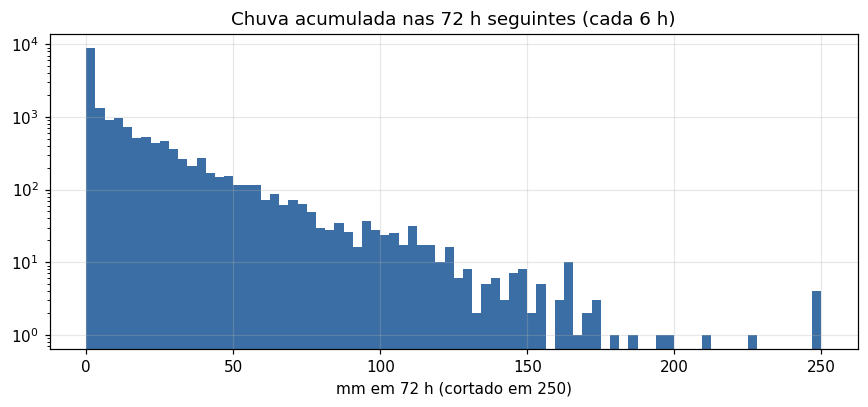

In [ ]:
# acumulado FUTURO de 72 h em (t, t+72h]: é o que o modelo tenta prever
def soma_futura(chuva, janela=JANELA_ALVO_H):
    idx = pd.api.indexers.FixedForwardWindowIndexer(window_size=janela)
    soma = chuva.fillna(0).rolling(idx, min_periods=1).sum().shift(-1)
    n_obs = chuva.notna().astype(float).rolling(idx, min_periods=1).sum().shift(-1)
    # janela com menos de 90% das horas observadas não vale como rótulo
    return soma.where(n_obs >= 0.9 * janela)

futura = soma_futura(chuva)
cada_6h = futura[futura.index.hour % PASSO_AMOSTRA_H == 0].dropna()
print(cada_6h.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(cada_6h.clip(upper=250), bins=80, color="#3b6ea5")
ax.set_yscale("log")
ax.set_title("Chuva acumulada nas 72 h seguintes (cada 6 h)")
ax.set_xlabel("mm em 72 h (cortado em 250)")
plt.tight_layout(); plt.show()

### Escolha do limiar do alvo

O limiar define o que conta como chuva forte em 72 h. A tabela abaixo usa só as linhas anteriores ao corte de teste. Um limiar muito alto deixa poucos eventos independentes e a métrica vira sorte (foi o problema do F1 de 0,29 em 6 eventos na GS1). Um limiar baixo demais vira chuva comum. Episódio aqui é um grupo de linhas positivas separadas por mais de 72 h das outras.

In [ ]:
antes = cada_6h[cada_6h.index <= CORTE_TESTE - pd.Timedelta(hours=JANELA_ALVO_H)]

def episodios(ts):
    if len(ts) == 0:
        return 0
    return int((ts.to_series().diff() > pd.Timedelta(hours=JANELA_ALVO_H)).sum() + 1)

linhas = []
for lim in [30, 40, 50, 60, 75, 100]:
    pos = antes[antes >= lim]
    linhas.append({"limiar_mm": lim, "linhas_positivas": len(pos),
                   "taxa_positivos": f"{len(pos) / len(antes):.1%}",
                   "episodios_independentes": episodios(pos.index)})
pd.DataFrame(linhas)

,limiar_mm,linhas_positivas,taxa_positivos,episodios_independentes
0,30,1841,14.1%,142
1,40,1252,9.6%,108
2,50,831,6.4%,81
3,60,547,4.2%,54
4,75,314,2.4%,35
5,100,145,1.1%,19


In [ ]:
# 50 mm em 72 h: ver a tabela acima. Se der menos de ~30 episódios no treino, baixe o limiar.
LIMIAR_MM = 50

## 5. Atributos e alvo

Cada atributo usa só observações até o instante t (janelas para trás). O alvo olha para frente. As linhas são amostradas de 6 em 6 horas para reduzir a repetição quase idêntica entre horas vizinhas.

In [ ]:
JANELAS = [1, 3, 6, 12, 24, 48, 72, 168]

def monta_atributos(h):
    f = pd.DataFrame(index=h.index)
    ch = h["chuva_mm"]
    for w in JANELAS:
        f[f"chuva_{w}h"] = ch.rolling(w, min_periods=max(1, int(w * 0.8))).sum()
    f["pressao"] = h["pressao_mb"]
    f["dpressao_3h"] = h["pressao_mb"].diff(3)
    f["dpressao_24h"] = h["pressao_mb"].diff(24)
    f["temp"] = h["temp_c"]
    f["umid"] = h["umid_pct"]
    f["dif_orvalho"] = h["temp_c"] - h["orvalho_c"]
    f["vento"] = h["vento_ms"]
    f["rajada"] = h["rajada_ms"]
    choveu = ch.fillna(0) > 0.1
    f["horas_sem_chuva"] = choveu.groupby(choveu.cumsum()).cumcount().clip(upper=240)
    doy = h.index.day_of_year
    f["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
    f["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)
    return f

atributos = monta_atributos(horario)
COLS = list(atributos.columns)

dados = atributos.join(futura.rename("chuva_futura_72h"))
dados = dados[dados.index.hour % PASSO_AMOSTRA_H == 0]
dados = dados.dropna(subset=["chuva_futura_72h"])
# linha com mais da metade dos atributos ausentes não ajuda nem o imputador
dados = dados[dados[COLS].isna().mean(axis=1) <= 0.5]
dados["alvo"] = (dados["chuva_futura_72h"] >= LIMIAR_MM).astype(int)

print("linhas:", len(dados), "| período:", dados.index.min().date(), "a", dados.index.max().date())
print("taxa de positivos:", f"{dados['alvo'].mean():.2%}")

linhas: 17334 | período: 2014-01-01 a 2025-12-29
taxa de positivos: 6.85%


## 6. Separação temporal, sem vazamento

Em série temporal não se embaralha. O treino vai até o fim de 2022 e o teste é 2023 a 2025. Dois cuidados evitam vazamento:

1. O alvo de uma linha olha 72 h para frente. Uma linha de treino nas últimas 72 h antes do corte teria o rótulo calculado com chuva que já pertence ao período de teste, então essas linhas saem do treino.
2. Na validação cruzada do tuning vamos usar `TimeSeriesSplit` com `gap` de 12 linhas (72 h na amostra de 6 em 6 h), pelo mesmo motivo.

O teste ficar no fim cai bem para o problema: ele inclui as chuvas de 2023 e de maio de 2024 no RS, eventos fora do que o modelo viu.

In [ ]:
fim_treino = CORTE_TESTE - pd.Timedelta(hours=JANELA_ALVO_H)
treino = dados[dados.index <= fim_treino]
teste = dados[dados.index >= CORTE_TESTE]

resumo = pd.DataFrame({
    "linhas": [len(treino), len(teste)],
    "positivos": [int(treino["alvo"].sum()), int(teste["alvo"].sum())],
    "taxa": [f"{treino['alvo'].mean():.1%}", f"{teste['alvo'].mean():.1%}"],
    "episodios": [episodios(treino.index[treino["alvo"] == 1]), episodios(teste.index[teste["alvo"] == 1])],
    "inicio": [treino.index.min().date(), teste.index.min().date()],
    "fim": [treino.index.max().date(), teste.index.max().date()],
}, index=["treino", "teste"])
print(resumo)
if teste["alvo"].sum() < 30:
    print("ATENÇÃO: poucos positivos no teste, a métrica final vai oscilar muito")

        linhas  positivos  taxa  episodios      inicio         fim
treino   13021        831  6.4%         81  2014-01-01  2022-12-29
teste     4302        357  8.3%         29  2023-01-01  2025-12-29


In [ ]:
# quais janelas o TimeSeriesSplit vai usar no tuning (gap de 72 h entre treino e validação)
tscv = TimeSeriesSplit(n_splits=5, gap=JANELA_ALVO_H // PASSO_AMOSTRA_H)
for i, (a, b) in enumerate(tscv.split(treino), 1):
    print(f"fold {i}: treina {treino.index[a[0]].date()} a {treino.index[a[-1]].date()} | "
          f"valida {treino.index[b[0]].date()} a {treino.index[b[-1]].date()} | "
          f"positivos na validação: {int(treino['alvo'].iloc[b].sum())}")

fold 1: treina 2014-01-01 a 2015-06-26 | valida 2015-06-30 a 2017-01-06 | positivos na validação: 197
fold 2: treina 2014-01-01 a 2017-01-03 | valida 2017-01-06 a 2018-07-08 | positivos na validação: 142
fold 3: treina 2014-01-01 a 2018-07-05 | valida 2018-07-08 a 2020-01-02 | positivos na validação: 136
fold 4: treina 2014-01-01 a 2019-12-30 | valida 2020-01-02 a 2021-07-04 | positivos na validação: 98
fold 5: treina 2014-01-01 a 2021-07-01 | valida 2021-07-04 a 2022-12-29 | positivos na validação: 124


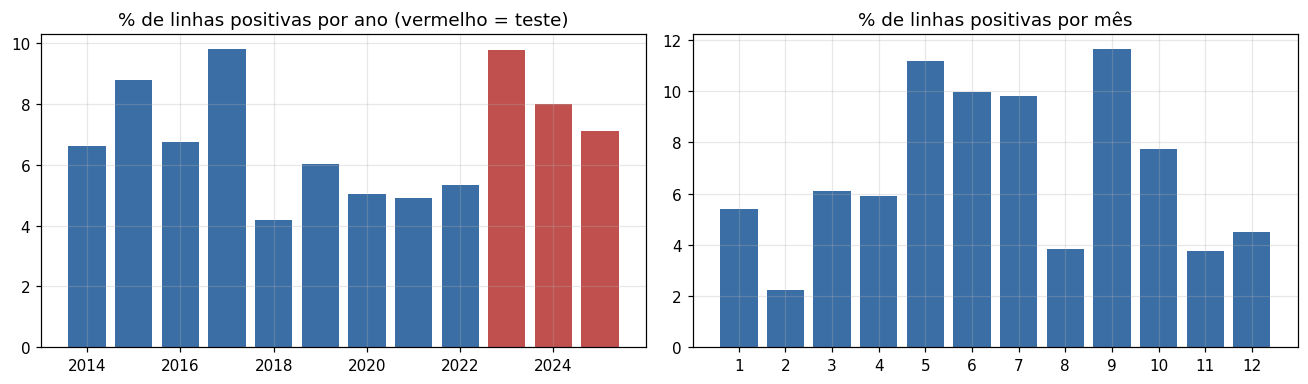

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
taxa_ano = dados["alvo"].groupby(dados.index.year).mean() * 100
cores = ["#3b6ea5" if y < CORTE_TESTE.year else "#c0504d" for y in taxa_ano.index]
axs[0].bar(taxa_ano.index, taxa_ano.values, color=cores)
axs[0].set_title("% de linhas positivas por ano (vermelho = teste)")
taxa_mes = dados["alvo"].groupby(dados.index.month).mean() * 100
axs[1].bar(taxa_mes.index, taxa_mes.values, color="#3b6ea5")
axs[1].set_title("% de linhas positivas por mês"); axs[1].set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

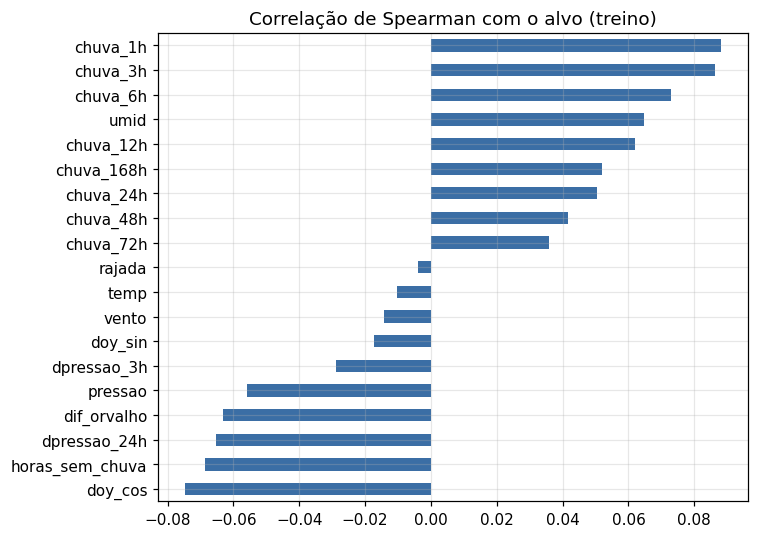

pares de atributos mais correlacionados entre si:
umid       dif_orvalho        1.00
vento      rajada             0.86
chuva_24h  horas_sem_chuva    0.85
chuva_3h   chuva_6h           0.85
chuva_48h  chuva_72h          0.84
chuva_6h   chuva_12h          0.83
dtype: float64


In [ ]:
# relação de cada atributo com o alvo, só no treino
corr = treino[COLS].corrwith(treino["alvo"], method="spearman").sort_values()
ax = corr.plot(kind="barh", figsize=(7, 5), color="#3b6ea5")
ax.set_title("Correlação de Spearman com o alvo (treino)")
plt.tight_layout(); plt.show()

cm = treino[COLS].corr(method="spearman")
pares = cm.where(np.triu(np.ones(cm.shape, dtype=bool), 1)).stack()
print("pares de atributos mais correlacionados entre si:")
print(pares.abs().sort_values(ascending=False).head(6).round(2))

## 7. Pré-processamento

Ausentes: o imputador usa a mediana calculada no treino. A padronização (média zero, desvio um) também aprende no treino. Os dois ficam num `Pipeline`, que na modelagem entra dentro da validação cruzada e é reajustado a cada fold. Para árvores e florestas a escala não muda nada, mas regressão logística e KNN dependem dela, e usar o mesmo pipeline para todos mantém a comparação justa.

In [ ]:
X_treino, y_treino = treino[COLS], treino["alvo"]
X_teste, y_teste = teste[COLS], teste["alvo"]

prep = Pipeline([
    ("imputa", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
])
Xt = prep.fit_transform(X_treino)
Xs = prep.transform(X_teste)

print("ausentes no treino por coluna (%):")
print((X_treino.isna().mean() * 100).round(1)[lambda s: s > 0])
print("\nmédia das colunas padronizadas no treino (deve ser ~0):", np.abs(Xt.mean(axis=0)).max().round(6))
print("média das colunas padronizadas no teste (não precisa ser 0):", np.abs(Xs.mean(axis=0)).max().round(3))

ausentes no treino por coluna (%):
chuva_1h        0.1
chuva_3h        0.1
chuva_6h        0.1
chuva_12h       0.1
chuva_24h       0.1
chuva_48h       0.2
chuva_72h       0.3
chuva_168h      0.6
pressao         0.1
dpressao_3h     0.2
dpressao_24h    0.4
temp            0.1
umid            0.1
dif_orvalho     0.1
vento           1.3
rajada          1.3
dtype: float64

média das colunas padronizadas no treino (deve ser ~0): 0.0
média das colunas padronizadas no teste (não precisa ser 0): 0.176


### Conferência anti-vazamento

In [ ]:
mediana_treino = X_treino.median().to_numpy()
media_treino = SimpleImputer(strategy="median").fit(X_treino).transform(X_treino).mean(axis=0)

checks = {
    "treino termina 72 h antes do teste": treino.index.max() + pd.Timedelta(hours=JANELA_ALVO_H) <= teste.index.min(),
    "treino e teste não compartilham horário": len(treino.index.intersection(teste.index)) == 0,
    "imputador aprendeu a mediana do treino": np.allclose(prep["imputa"].statistics_, mediana_treino, equal_nan=True),
    "escalador aprendeu a média do treino": np.allclose(prep["escala"].mean_, media_treino),
    "o alvo não está entre os atributos": "alvo" not in COLS and "chuva_futura_72h" not in COLS,
    "nenhum atributo usa janela futura": all(not c.endswith("futura_72h") for c in COLS),
}
for nome, ok in checks.items():
    print("ok " if ok else "FALHOU", nome)
assert all(checks.values())

ok  treino termina 72 h antes do teste
ok  treino e teste não compartilham horário
ok  imputador aprendeu a mediana do treino
ok  escalador aprendeu a média do treino
ok  o alvo não está entre os atributos
ok  nenhum atributo usa janela futura


## Resumo do pré-processamento

- Base: INMET A801, 2014 a 2025, horária, com as lacunas medidas na seção 3.
- Alvo: chuva acumulada em 72 h à frente maior ou igual a `LIMIAR_MM` (plano B, registrado no relatório).
- Treino até 2022 (menos 72 h de margem) e teste de 2023 em diante. Validação do tuning com `TimeSeriesSplit` e `gap`.
- Imputação e padronização aprendidas só no treino, dentro de `Pipeline`.
- Limitações: estação única, horários em UTC, alvo que aproxima o risco em vez de medir o nível do rio, e poucos episódios extremos no teste.

As próximas seções trazem os baselines, os modelos e o tuning e, depois, importância das variáveis, modelo final e aplicação.

## 8. Métrica e baselines

A métrica principal é a PR-AUC (`average_precision_score`), a área sob a curva de precisão por recall. Com 6% a 8% de linhas positivas, a acurácia premia quem responde "não vai alagar" o tempo todo, e a ROC-AUC fica otimista quando a classe rara é pequena. Na PR-AUC, um modelo sem informação nenhuma empata com a taxa de positivos, então esse número é o piso para ler todo o resto. Recall e precisão entram em um limiar de decisão, que é onde o morador sente o custo: recall baixo é alarme perdido, precisão baixa é alarme falso.

Dois baselines. O primeiro não usa informação nenhuma e prevê sempre a taxa de positivos do treino. O segundo é a persistência, a regra que uma pessoa usaria sem ML: se choveu `LIMIAR_MM` ou mais nas últimas 72 h, assume que vai chover o mesmo nas próximas 72 h. Um modelo que não ganha da persistência não compensa a complexidade.

Toda nota de validação vem do `TimeSeriesSplit` da seção 6 (5 dobras, `gap` de 72 h). A nota de cada modelo é a média da PR-AUC nas dobras de validação, junto com o desvio entre elas. O teste só aparece na seção 11.

In [ ]:
import time
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             recall_score, precision_score)

def pipe(modelo, escala=True):
    passos = [("imputa", SimpleImputer(strategy="median"))]
    if escala:
        passos.append(("escala", StandardScaler()))
    return Pipeline(passos + [("modelo", modelo)])


# chuva das últimas 72 h usada como se fosse a das próximas 72 h; dá 0,5 quando choveu LIMIAR_MM
class Persistencia(BaseEstimator, ClassifierMixin):
    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        s = X["chuva_72h"].fillna(0).to_numpy()
        p = s / (s + LIMIAR_MM)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


folds = list(tscv.split(X_treino))
res = {}

def valida(estimador):
    # cada dobra é prevista por um modelo treinado só com o que veio antes dela
    oof = pd.Series(np.nan, index=X_treino.index)
    for ajuste, validacao in folds:
        m = clone(estimador).fit(X_treino.iloc[ajuste], y_treino.iloc[ajuste])
        oof.iloc[validacao] = m.predict_proba(X_treino.iloc[validacao])[:, 1]
    return oof

def registra(nome, estimador):
    final = clone(estimador).fit(X_treino, y_treino)
    oof = valida(estimador)
    dobras = np.array([average_precision_score(y_treino.iloc[v], oof.iloc[v]) for _, v in folds])
    res[nome] = {"modelo": final, "oof": oof, "dobras": dobras,
                 "p_treino": final.predict_proba(X_treino)[:, 1]}

def tabela_validacao(nomes):
    linhas = {n: {"PR-AUC treino": average_precision_score(y_treino, res[n]["p_treino"]),
                  "PR-AUC validação": res[n]["dobras"].mean(),
                  "desvio entre dobras": res[n]["dobras"].std()} for n in nomes}
    return pd.DataFrame(linhas).T.round(3)

registra("Sem informação", DummyClassifier(strategy="prior"))
registra("Persistência 72 h", Persistencia())

print(f"taxa de positivos: treino {y_treino.mean():.3f} | teste {y_teste.mean():.3f}")
tabela_validacao(["Sem informação", "Persistência 72 h"])

taxa de positivos: treino 0.064 | teste 0.083


,PR-AUC treino,PR-AUC validação,desvio entre dobras
Sem informação,0.064,0.064,0.015
Persistência 72 h,0.068,0.073,0.025


## 9. Modelos candidatos

Três algoritmos, cada um por um motivo. A regressão logística é linear e interpretável, com atributos padronizados: mostra se há uma relação simples entre chuva acumulada, pressão e o alvo e serve de piso para os modelos de árvore. A Random Forest pega interações (chuva acumulada alta junto com queda de pressão, por exemplo) sem depender de escala e convive bem com atributos muito correlacionados, como os da seção 6. O Gradient Boosting (`HistGradientBoostingClassifier`) treina árvores rasas em sequência, aceita ausentes e costuma ser o mais forte em dado tabular. Fica dentro do scikit-learn, então não exige instalar nada no Colab.

O desbalanceamento é tratado com `class_weight` e não com reamostragem. SMOTE criaria linhas sintéticas misturando horários diferentes e quebraria a ordem do tempo.

Aqui todos entram com os hiperparâmetros padrão (só com o peso de classe). O ajuste vem na seção 10.

In [ ]:
padrao = {
    "Regressão logística (padrão)": pipe(LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
    "Random Forest (padrão)": pipe(RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                           n_jobs=-1, random_state=SEED), escala=False),
    "Gradient Boosting (padrão)": pipe(HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
                                       escala=False),
}
for nome, est in padrao.items():
    registra(nome, est)

tabela_validacao(["Sem informação", "Persistência 72 h"] + list(padrao))

,PR-AUC treino,PR-AUC validação,desvio entre dobras
Sem informação,0.064,0.064,0.015
Persistência 72 h,0.068,0.073,0.025
Regressão logística (padrão),0.137,0.110,0.022
Random Forest (padrão),1.000,0.099,0.027
Gradient Boosting (padrão),0.967,0.096,0.024


## 10. Tuning de hiperparâmetros

Cada modelo passa por uma busca com a mesma validação temporal da seção 6 (`TimeSeriesSplit` com `gap` de 72 h) e `scoring="average_precision"`:

- Regressão logística: `GridSearchCV` em `C` e no peso de classe (14 combinações).
- Random Forest e Gradient Boosting: `RandomizedSearchCV` com 20 e 25 sorteios.

Os espaços de busca limitam a complexidade das árvores (profundidade, tamanho mínimo de folha, `max_samples`, regularização L2), porque a tabela da seção 9 mostra o que acontece sem isso: nota quase perfeita no treino e muito menor na validação. Ao fim da busca, o melhor conjunto é reajustado no treino inteiro. O teste continua intocado.

In [ ]:
busca_log = GridSearchCV(
    pipe(LogisticRegression(max_iter=3000, random_state=SEED)),
    {"modelo__C": [0.001, 0.01, 0.03, 0.1, 0.3, 1, 10], "modelo__class_weight": ["balanced", None]},
    scoring="average_precision", cv=tscv, n_jobs=-1)

busca_rf = RandomizedSearchCV(
    pipe(RandomForestClassifier(n_estimators=300, random_state=SEED), escala=False),
    {"modelo__max_depth": [3, 4, 6, 8, 12], "modelo__min_samples_leaf": [10, 25, 50, 100, 200],
     "modelo__max_features": ["sqrt", 0.3, 0.5], "modelo__max_samples": [0.3, 0.5, 0.8],
     "modelo__class_weight": ["balanced_subsample", None]},
    n_iter=20, scoring="average_precision", cv=tscv, n_jobs=-1, random_state=SEED)

busca_gb = RandomizedSearchCV(
    pipe(HistGradientBoostingClassifier(early_stopping=False, random_state=SEED), escala=False),
    {"modelo__learning_rate": [0.01, 0.03, 0.05, 0.1], "modelo__max_iter": [100, 200, 400],
     "modelo__max_depth": [2, 3, 4], "modelo__max_leaf_nodes": [4, 8, 15],
     "modelo__min_samples_leaf": [50, 100, 200, 400], "modelo__l2_regularization": [0, 1, 10],
     "modelo__class_weight": ["balanced", None]},
    n_iter=25, scoring="average_precision", cv=tscv, n_jobs=-1, random_state=SEED)

buscas = {"Regressão logística": busca_log, "Random Forest": busca_rf, "Gradient Boosting": busca_gb}
for nome, b in buscas.items():
    t0 = time.time()
    b.fit(X_treino, y_treino)
    print(f"{nome}: melhor PR-AUC na validação {b.best_score_:.3f} ({time.time() - t0:.0f} s)")
    print("   ", {k.replace("modelo__", ""): v for k, v in b.best_params_.items()})

Regressão logística: melhor PR-AUC na validação 0.115 (7 s)
    {'C': 0.01, 'class_weight': None}
Random Forest: melhor PR-AUC na validação 0.117 (208 s)
    {'min_samples_leaf': 10, 'max_samples': 0.8, 'max_features': 0.3, 'max_depth': 4, 'class_weight': 'balanced_subsample'}
Gradient Boosting: melhor PR-AUC na validação 0.112 (41 s)
    {'min_samples_leaf': 200, 'max_leaf_nodes': 15, 'max_iter': 400, 'max_depth': 2, 'learning_rate': 0.01, 'l2_regularization': 1, 'class_weight': 'balanced'}


In [ ]:
# cinco melhores candidatos de cada busca: se a diferença cabe no desvio, o "melhor" é só o primeiro da fila
for nome, b in buscas.items():
    topo = pd.DataFrame(b.cv_results_).sort_values("rank_test_score").head(5)
    print(nome)
    print(topo[["mean_test_score", "std_test_score"]].round(3).to_string(index=False), "\n")

for nome, b in buscas.items():
    registra(f"{nome} (ajustada)", b.best_estimator_)
    # o reajuste tem que reproduzir a nota da busca
    assert abs(res[f"{nome} (ajustada)"]["dobras"].mean() - b.best_score_) < 1e-6

ordem = ["Sem informação", "Persistência 72 h"] + [f"{m} ({v})" for m in buscas for v in ("padrão", "ajustada")]
tabela_validacao(ordem)

Regressão logística
 mean_test_score  std_test_score
           0.115           0.029
           0.113           0.029
           0.113           0.026
           0.111           0.027
           0.111           0.027 

Random Forest
 mean_test_score  std_test_score
           0.117           0.044
           0.116           0.036
           0.116           0.045
           0.115           0.039
           0.113           0.036 

Gradient Boosting
 mean_test_score  std_test_score
           0.112           0.036
           0.110           0.033
           0.110           0.037
           0.109           0.031
           0.108           0.032 



,PR-AUC treino,PR-AUC validação,desvio entre dobras
Sem informação,0.064,0.064,0.015
Persistência 72 h,0.068,0.073,0.025
Regressão logística (padrão),0.137,0.110,0.022
Regressão logística (ajustada),0.142,0.115,0.029
Random Forest (padrão),1.000,0.099,0.027
Random Forest (ajustada),0.229,0.117,0.044
Gradient Boosting (padrão),0.967,0.096,0.024
Gradient Boosting (ajustada),0.209,0.112,0.036


## 11. Avaliação no teste (2023 a 2025)

O teste é usado agora, uma vez, com os modelos já fechados. Nenhum hiperparâmetro nem limiar foi escolhido olhando esse período.

Como o teste tem poucos episódios independentes de chuva forte, a PR-AUC vem com um intervalo de confiança de 95% por bootstrap em blocos mensais (sorteia meses inteiros com reposição, para respeitar a correlação entre horas vizinhas). Sem o intervalo, uma diferença de 0,01 entre modelos pareceria resultado.

In [ ]:
for r in res.values():
    r["p_teste"] = r["modelo"].predict_proba(X_teste)[:, 1]

pos_teste = teste.index[teste["alvo"] == 1]
print(f"teste: {int(y_teste.sum())} linhas positivas em {episodios(pos_teste)} episódios independentes "
      f"(taxa {y_teste.mean():.3f})")

# os mesmos sorteios de meses para todos os modelos, então a comparação é pareada
meses = teste.index.to_period("M")
blocos = [np.flatnonzero(meses == m) for m in meses.unique()]
rng = np.random.default_rng(SEED)
sorteios = [rng.integers(0, len(blocos), len(blocos)) for _ in range(500)]
y_arr = y_teste.to_numpy()

def ic_pr(p):
    notas = []
    for s in sorteios:
        idx = np.concatenate([blocos[i] for i in s])
        if y_arr[idx].sum() > 0:
            notas.append(average_precision_score(y_arr[idx], p[idx]))
    return np.percentile(notas, [2.5, 97.5])

linhas = {}
for nome in ordem:
    r = res[nome]
    lo, hi = ic_pr(r["p_teste"])
    linhas[nome] = {"PR-AUC treino": average_precision_score(y_treino, r["p_treino"]),
                    "PR-AUC validação": r["dobras"].mean(),
                    "PR-AUC teste": average_precision_score(y_teste, r["p_teste"]),
                    "IC 95% do teste": f"{lo:.3f} a {hi:.3f}",
                    "ROC-AUC teste": roc_auc_score(y_teste, r["p_teste"])}
tab_teste = pd.DataFrame(linhas).T
num = [c for c in tab_teste.columns if c != "IC 95% do teste"]
tab_teste[num] = tab_teste[num].astype(float).round(3)
tab_teste

teste: 357 linhas positivas em 29 episódios independentes (taxa 0.083)


,PR-AUC treino,PR-AUC validação,PR-AUC teste,IC 95% do teste,ROC-AUC teste
Sem informação,0.064,0.064,0.083,0.052 a 0.117,0.500
Persistência 72 h,0.068,0.073,0.120,0.073 a 0.170,0.598
Regressão logística (padrão),0.137,0.110,0.201,0.130 a 0.284,0.732
Regressão logística (ajustada),0.142,0.115,0.203,0.129 a 0.277,0.731
Random Forest (padrão),1.000,0.099,0.154,0.092 a 0.238,0.638
Random Forest (ajustada),0.229,0.117,0.201,0.122 a 0.290,0.658
Gradient Boosting (padrão),0.967,0.096,0.127,0.070 a 0.196,0.596
Gradient Boosting (ajustada),0.209,0.112,0.183,0.119 a 0.254,0.666


In [ ]:
# intervalos que se sobrepõem não decidem nada; a diferença pareada nos mesmos sorteios de meses decide melhor
def ic_diferenca(p, q):
    d = []
    for s in sorteios:
        idx = np.concatenate([blocos[i] for i in s])
        if y_arr[idx].sum() > 0:
            d.append(average_precision_score(y_arr[idx], p[idx]) - average_precision_score(y_arr[idx], q[idx]))
    return np.percentile(d, [2.5, 97.5])

pares = [(m, "Persistência 72 h") for m in [f"{m} (ajustada)" for m in buscas]] + [
    ("Random Forest (ajustada)", "Regressão logística (ajustada)"),
    ("Gradient Boosting (ajustada)", "Regressão logística (ajustada)")]
for a, b in pares:
    lo, hi = ic_diferenca(res[a]["p_teste"], res[b]["p_teste"])
    print(f"{a} menos {b}: diferença de PR-AUC entre {lo:+.3f} e {hi:+.3f}")

Regressão logística (ajustada) menos Persistência 72 h: diferença de PR-AUC entre +0.025 e +0.147
Random Forest (ajustada) menos Persistência 72 h: diferença de PR-AUC entre +0.016 e +0.143
Gradient Boosting (ajustada) menos Persistência 72 h: diferença de PR-AUC entre +0.011 e +0.116
Random Forest (ajustada) menos Regressão logística (ajustada): diferença de PR-AUC entre -0.075 e +0.065
Gradient Boosting (ajustada) menos Regressão logística (ajustada): diferença de PR-AUC entre -0.082 e +0.029


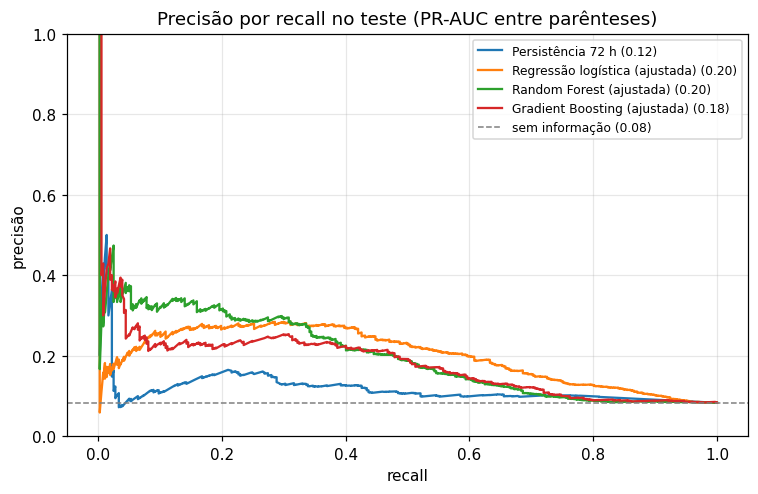

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.6))
curvas = ["Persistência 72 h"] + [f"{m} (ajustada)" for m in buscas]
for nome in curvas:
    prec, rec, _ = precision_recall_curve(y_teste, res[nome]["p_teste"])
    ax.plot(rec, prec, label=f"{nome} ({average_precision_score(y_teste, res[nome]['p_teste']):.2f})")
ax.axhline(y_teste.mean(), color="gray", ls="--", lw=1, label=f"sem informação ({y_teste.mean():.2f})")
ax.set_xlabel("recall"); ax.set_ylabel("precisão"); ax.set_ylim(0, 1)
ax.set_title("Precisão por recall no teste (PR-AUC entre parênteses)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Recall e precisão em um limiar de decisão

A PR-AUC não diz o que acontece quando o aviso dispara de verdade. Para isso fixo um critério de operação, escolhido só com as previsões fora da amostra do treino: o maior limiar que ainda captura 70% dos eventos na validação (`RECALL_ALVO`). Esse limiar é aplicado no teste sem mudança. Ao lado, o limiar padrão de 0,5, que é o que cada modelo usaria se ninguém mexesse.

A confirmação do limiar e a escolha do modelo final ficam para as seções 14 e 15.

In [ ]:
RECALL_ALVO = 0.70
finais = ["Persistência 72 h"] + [f"{m} (ajustada)" for m in buscas]

def limiar_do_recall(oof):
    ok = oof.notna()
    prec, rec, thr = precision_recall_curve(y_treino[ok], oof[ok])
    return thr[rec[:-1] >= RECALL_ALVO].max()

linhas = {}
for nome in finais:
    p = res[nome]["p_teste"]
    lim = limiar_do_recall(res[nome]["oof"])
    a, b = p >= 0.5, p >= lim
    linhas[nome] = {"recall (0,5)": recall_score(y_teste, a),
                    "precisão (0,5)": precision_score(y_teste, a, zero_division=0),
                    "limiar da validação": lim,
                    "recall": recall_score(y_teste, b),
                    "precisão": precision_score(y_teste, b, zero_division=0),
                    "linhas sinalizadas": b.mean()}
print("sem informação: nunca dispara, recall 0,00")
pd.DataFrame(linhas).T.round(3)

sem informação: nunca dispara, recall 0,00


,"recall (0,5)","precisão (0,5)",limiar da validação,recall,precisão,linhas sinalizadas
Persistência 72 h,0.109,0.113,0.008,0.723,0.100,0.598
Regressão logística (ajustada),0.003,1.000,0.054,0.759,0.130,0.486
Random Forest (ajustada),0.529,0.170,0.345,0.779,0.091,0.714
Gradient Boosting (ajustada),0.594,0.150,0.344,0.798,0.091,0.732


In [ ]:
ajustadas = [n for n in res if n.endswith("(ajustada)")]
nota_val = {n: res[n]["dobras"].mean() for n in ajustadas}
nota_teste = {n: average_precision_score(y_teste, res[n]["p_teste"]) for n in ajustadas}
print("melhor na validação:", max(nota_val, key=nota_val.get), round(max(nota_val.values()), 3))
print("melhor no teste:    ", max(nota_teste, key=nota_teste.get), round(max(nota_teste.values()), 3))
pers = average_precision_score(y_teste, res["Persistência 72 h"]["p_teste"])
print(f"persistência no teste: {pers:.3f} | taxa de positivos: {y_teste.mean():.3f}")

melhor na validação: Random Forest (ajustada) 0.117
melhor no teste:     Regressão logística (ajustada) 0.203
persistência no teste: 0.120 | taxa de positivos: 0.083


### Leitura da avaliação no teste

Os números abaixo são os da execução com `SEED = 42`. Em outra versão do scikit-learn podem mudar na terceira casa.

Os três modelos ajustados ganham dos baselines, mas por pouco em valor absoluto. Na validação a PR-AUC fica entre 0,11 e 0,12, contra 0,064 do modelo sem informação e 0,073 da persistência. No teste fica entre 0,18 e 0,20, com taxa de positivos de 0,083. Contra a persistência, o limite inferior do intervalo de 95% da diferença pareada fica entre +0,01 e +0,03, acima de zero nos três casos.

Nenhum modelo se separa dos outros. Os cinco melhores candidatos de cada busca ficam a menos de 0,01 entre si, o desvio entre dobras (0,03 a 0,04) é maior que a distância entre os modelos, e os intervalos das diferenças pareadas no teste incluem o zero. Escolher o modelo final pela terceira casa decimal seria sorte. A escolha do modelo final, na seção 15, leva em conta também a interpretação e o comportamento do limiar.

Sobre sobreajuste: com os hiperparâmetros padrão, Random Forest e Gradient Boosting decoram o treino (PR-AUC de 1,00 e 0,95, contra 0,10 e 0,09 na validação). O tuning limita profundidade e tamanho de folha, derruba a nota de treino para 0,21 a 0,23 e sobe um pouco a de validação. A regressão logística quase não sobreajusta (0,14 no treino, 0,115 na validação) e quase não ganha com o tuning, indício de que o limite está nos atributos e não no algoritmo.

Validação (0,11) e teste (0,20) não se comparam direto, porque a PR-AUC sobe junto com a taxa de positivos (6,4% no treino, 8,3% no teste). O que vale é o ganho sobre o acaso: cerca de 1,8 vez na validação e 2,4 vezes no teste para a logística.

O limiar mostra o custo real. Com o limiar tirado da validação para 70% de recall, o teste fica entre 0,76 e 0,79 de recall nos três modelos, mas com precisão de 0,09 a 0,13, pouco acima da taxa de positivos, e o aviso dispararia em 49% a 75% das linhas. A logística é a menos ruim (recall 0,76, precisão 0,13, 49% das linhas). No limiar de 0,5 ela, sem peso de classe, quase nunca dispara (recall 0,003), o que mostra por que 0,5 não serve para uma classe rara.

Limitações: uma estação só, um alvo que aproxima o risco em vez de medir o alagamento, e 29 episódios independentes no teste, o que explica os intervalos largos.

## 12. Importância das variáveis

Duas leituras do mesmo problema. Os coeficientes da regressão logística (atributos já padronizados, então comparáveis entre si) mostram o sentido do efeito. A importância por permutação mostra quanto a PR-AUC do teste cai quando se embaralha uma variável, sem refazer o treino.

As variáveis de chuva acumulada são muito correlacionadas entre si (seção 6). Embaralhar uma de cada vez cria linhas que nenhum dia real produziria e exagera o efeito, e os coeficientes se compensam entre colunas parecidas. Por isso a permutação é feita por grupo de variáveis, com a mesma ordem embaralhada para todas as colunas do grupo. Repete-se 20 vezes e mostra-se o desvio.

A permutação usa o teste só para interpretar. Nada que já foi decidido (hiperparâmetros, limiar) volta atrás por causa dela.

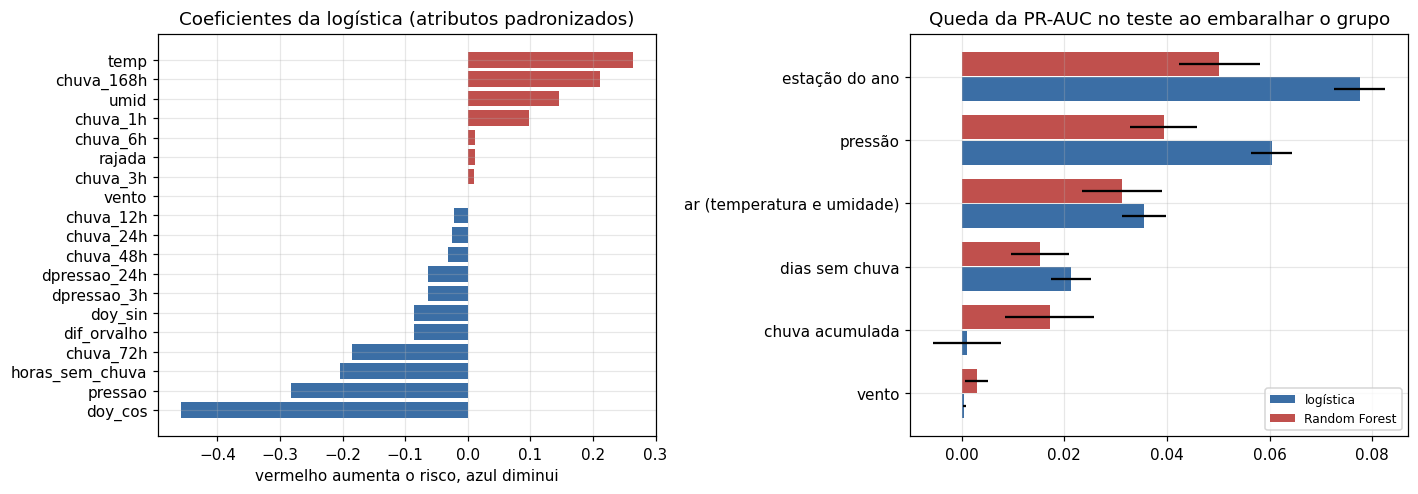

logística         Random Forest        
                               queda  desvio         queda  desvio
chuva acumulada               0.0011  0.0067        0.0171  0.0086
pressão                       0.0604  0.0040        0.0393  0.0066
ar (temperatura e umidade)    0.0355  0.0043        0.0312  0.0078
vento                         0.0005  0.0002        0.0029  0.0023
dias sem chuva                0.0213  0.0040        0.0152  0.0056
estação do ano                0.0776  0.0050        0.0502  0.0080

In [ ]:
final = res["Regressão logística (ajustada)"]["modelo"]
floresta = res["Random Forest (ajustada)"]["modelo"]

GRUPOS = {
    "chuva acumulada": [c for c in COLS if c.startswith("chuva_")],
    "pressão": ["pressao", "dpressao_3h", "dpressao_24h"],
    "ar (temperatura e umidade)": ["temp", "umid", "dif_orvalho"],
    "vento": ["vento", "rajada"],
    "dias sem chuva": ["horas_sem_chuva"],
    "estação do ano": ["doy_sin", "doy_cos"],
}
assert sorted(sum(GRUPOS.values(), [])) == sorted(COLS)

def queda_por_permutacao(modelo, repeticoes=20):
    rng = np.random.default_rng(SEED)
    base = average_precision_score(y_teste, modelo.predict_proba(X_teste)[:, 1])
    saida = {}
    for nome, cols in GRUPOS.items():
        quedas = []
        for _ in range(repeticoes):
            X = X_teste.copy()
            X[cols] = X_teste[cols].to_numpy()[rng.permutation(len(X))]
            quedas.append(base - average_precision_score(y_teste, modelo.predict_proba(X)[:, 1]))
        saida[nome] = (np.mean(quedas), np.std(quedas))
    return pd.DataFrame(saida, index=["queda", "desvio"]).T

imp = pd.concat({"logística": queda_por_permutacao(final), "Random Forest": queda_por_permutacao(floresta)}, axis=1)
coef = pd.Series(final["modelo"].coef_[0], index=COLS).sort_values()

ordem_g = imp[("logística", "queda")].sort_values().index
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
axs[0].barh(coef.index, coef.values, color=np.where(coef.values > 0, "#c0504d", "#3b6ea5"))
axs[0].set_title("Coeficientes da logística (atributos padronizados)")
axs[0].set_xlabel("vermelho aumenta o risco, azul diminui")
y = np.arange(len(ordem_g))
for desloc, nome, cor in [(-0.2, "logística", "#3b6ea5"), (0.2, "Random Forest", "#c0504d")]:
    axs[1].barh(y + desloc, imp.loc[ordem_g, (nome, "queda")], height=0.38,
                xerr=imp.loc[ordem_g, (nome, "desvio")], color=cor, label=nome)
axs[1].set_yticks(y); axs[1].set_yticklabels(ordem_g)
axs[1].set_title("Queda da PR-AUC no teste ao embaralhar o grupo")
axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
imp.round(4)

### Leitura da importância

Estação do ano, pressão e o grupo do ar (temperatura e umidade) são os três que mais pesam nos dois modelos, e na mesma ordem. Na regressão logística, embaralhar a estação do ano derruba a PR-AUC do teste em 0,078, a pressão em 0,060 e o ar em 0,036. Os dias sem chuva vêm depois (0,021). A chuva acumulada pesa 0,001, com desvio de 0,007, o que não se distingue de zero, e o vento não pesa. A Random Forest repete a ordem dos três primeiros, mas usa um pouco mais a chuva acumulada (0,018).

Nos coeficientes, o sentido bate com a física. Pressão mais baixa e temperatura mais alta aumentam o risco. Seno e cosseno do dia do ano, juntos, colocam o pico de risco por volta de meados de julho. Para a chuva, a janela de 168 h sobe o risco (+0,21) e as de 72 h e de 24 h o diminuem. Isso é o efeito de colunas muito correlacionadas se compensando, então os coeficientes de chuva não devem ser lidos um a um.

Dois cuidados na leitura. O desvio da permutação é de 0,004 a 0,009 nos grupos grandes, então a ordem entre pressão e ar na Random Forest não é firme. E a permutação mede o que o modelo usa para prever, o que não prova que a variável cause a chuva.

## 13. O que o modelo realmente aprendeu

Se estação do ano, pressão e temperatura carregam o sinal, um modelo com só esses atributos deveria chegar perto do completo. A tabela testa isso com a mesma regressão logística ajustada (mesmos hiperparâmetros), mesmas dobras e conjuntos de atributos cada vez maiores. A nota de validação é a que decide. O teste aparece só para conferência.

In [ ]:
params_lr = {k.replace("modelo__", ""): v for k, v in busca_log.best_params_.items()}
conjuntos = {
    "só estação do ano": GRUPOS["estação do ano"],
    "estação + pressão": GRUPOS["estação do ano"] + GRUPOS["pressão"],
    "estação + pressão + ar": GRUPOS["estação do ano"] + GRUPOS["pressão"] + GRUPOS["ar (temperatura e umidade)"],
    "só chuva acumulada e dias sem chuva": GRUPOS["chuva acumulada"] + GRUPOS["dias sem chuva"],
    "todos os atributos": COLS,
}
linhas = {"sem informação (acaso)": {"atributos": 0, "PR-AUC validação": res["Sem informação"]["dobras"].mean(),
                                      "desvio entre dobras": res["Sem informação"]["dobras"].std(),
                                      "PR-AUC teste": y_teste.mean()}}
for nome, cols in conjuntos.items():
    est = pipe(LogisticRegression(max_iter=3000, random_state=SEED, **params_lr))
    notas = []
    for ajuste, validacao in folds:
        m = clone(est).fit(X_treino.iloc[ajuste][cols], y_treino.iloc[ajuste])
        notas.append(average_precision_score(y_treino.iloc[validacao], m.predict_proba(X_treino.iloc[validacao][cols])[:, 1]))
    m = clone(est).fit(X_treino[cols], y_treino)
    linhas[nome] = {"atributos": len(cols), "PR-AUC validação": np.mean(notas), "desvio entre dobras": np.std(notas),
                    "PR-AUC teste": average_precision_score(y_teste, m.predict_proba(X_teste[cols])[:, 1])}
pd.DataFrame(linhas).T.round(3)

,atributos,PR-AUC validação,desvio entre dobras,PR-AUC teste
sem informação (acaso),0.0,0.064,0.015,0.083
só estação do ano,2.0,0.123,0.069,0.112
estação + pressão,5.0,0.103,0.015,0.194
estação + pressão + ar,8.0,0.103,0.020,0.223
só chuva acumulada e dias sem chuva,9.0,0.100,0.025,0.127
todos os atributos,19.0,0.115,0.029,0.203


### Leitura da comparação

Nenhum conjunto de atributos ganha do modelo completo na validação, e o mais simples de todos, só a estação do ano, tem a maior nota (0,123 contra 0,115). O desvio entre dobras desse modelo é 0,069, o que mostra como essa nota é instável. Todos ficam entre 0,100 e 0,123, contra 0,064 do acaso. Boa parte do ganho sobre o acaso é climatologia: em Porto Alegre as chuvas fortes se concentram em certas épocas do ano, e saber a data já ajuda.

No teste a ordem muda. A estação sozinha vai a 0,112, e os conjuntos com pressão e ar chegam a 0,194 e 0,223, acima dos 0,203 do modelo completo. Isso sugere que pressão e temperatura trazem algum sinal além da data. O teste tem 29 episódios e a validação não confirma, então o conjunto de atributos não muda por causa dele. Escolher o conjunto olhando o teste seria usar o teste duas vezes.

A chuva acumulada com dias sem chuva chega a 0,127 no teste e 0,100 na validação, perto da persistência da seção 8 (0,120 e 0,073). O histórico recente de chuva traz pouca informação sobre as 72 h seguintes, ao menos nesta estação e com estes atributos.

## 14. Limiar de decisão e faixas de risco

Até aqui o limiar foi fixado em um critério só (70% de recall na validação). Esta seção mostra o que cada critério custa e transforma a probabilidade em três faixas, que combinam com os níveis do nó (OK, ATENÇÃO, ALERTA).

A faixa de atenção começa no limiar que captura 70% dos eventos na validação. Serve para quem quer ser avisado de condições favoráveis e aceita muito aviso sem evento. A faixa de alerta começa no menor limiar em que a precisão da validação chega a 15% (`PRECISAO_ALERTA`), cerca de 2,4 vezes a taxa de eventos do treino. Dispara pouco e, quando dispara, acerta mais.

Todos os limiares saem das previsões fora da amostra do treino (as mesmas das seções 8 a 11). O teste só mede o resultado.

In [ ]:
oof_final = res["Regressão logística (ajustada)"]["oof"]
p_final = res["Regressão logística (ajustada)"]["p_teste"]
ok = oof_final.notna()
prec_v, rec_v, thr_v = precision_recall_curve(y_treino[ok], oof_final[ok])

pos_teste = teste.index[teste["alvo"] == 1]
grupo_ep = (pos_teste.to_series().diff() > pd.Timedelta(hours=JANELA_ALVO_H)).cumsum().to_numpy()
n_episodios = len(np.unique(grupo_ep))

def episodios_detectados(sinal):
    marcado = pd.Series(np.asarray(sinal), index=teste.index).loc[pos_teste].to_numpy()
    return int(pd.Series(marcado).groupby(grupo_ep).any().sum())

linhas = {}
for alvo in [0.5, 0.6, 0.7, 0.8, 0.9]:
    lim = thr_v[rec_v[:-1] >= alvo].max()
    b = p_final >= lim
    linhas[f"recall {alvo:.0%} na validação"] = {
        "limiar": lim, "recall no teste": recall_score(y_teste, b),
        "precisão no teste": precision_score(y_teste, b, zero_division=0),
        "linhas sinalizadas": b.mean(),
        f"episódios detectados (de {n_episodios})": episodios_detectados(b)}
pd.DataFrame(linhas).T.round(3)

,limiar,recall no teste,precisão no teste,linhas sinalizadas,episódios detectados (de 29)
recall 50% na validação,0.072,0.633,0.189,0.278,26.0
recall 60% na validação,0.063,0.686,0.157,0.364,26.0
recall 70% na validação,0.054,0.759,0.130,0.486,29.0
recall 80% na validação,0.046,0.860,0.115,0.620,29.0
recall 90% na validação,0.037,0.910,0.100,0.757,29.0


In [ ]:
PRECISAO_ALERTA = 0.15
LIM_ATENCAO = thr_v[rec_v[:-1] >= 0.70].max()
LIM_ALERTA = thr_v[prec_v[:-1] >= PRECISAO_ALERTA].min()
print(f"limiar de atenção {LIM_ATENCAO:.4f} | limiar de alerta {LIM_ALERTA:.4f}")

def faixa(prob):
    return np.where(prob >= LIM_ALERTA, "alerta", np.where(prob >= LIM_ATENCAO, "atenção", "baixo"))

f_teste = faixa(p_final)
tab = pd.DataFrame({"faixa": f_teste, "alvo": y_teste.to_numpy()}).groupby("faixa").agg(linhas=("alvo", "size"), eventos=("alvo", "sum"))
tab = tab.reindex(["baixo", "atenção", "alerta"])
tab["% das linhas"] = tab["linhas"] / len(p_final)
tab["taxa de eventos"] = tab["eventos"] / tab["linhas"]
tab["% dos eventos"] = tab["eventos"] / y_teste.sum()
print(tab.round(3).to_string())
print(f"episódios com ao menos uma linha em atenção ou alerta: {episodios_detectados(p_final >= LIM_ATENCAO)} de {n_episodios}")
print(f"episódios com ao menos uma linha em alerta: {episodios_detectados(p_final >= LIM_ALERTA)} de {n_episodios}")

limiar de atenção 0.0537 | limiar de alerta 0.1311
         linhas  eventos  % das linhas  taxa de eventos  % dos eventos
faixa                                                                 
baixo      2210       86         0.514            0.039          0.241
atenção    1828      200         0.425            0.109          0.560
alerta      264       71         0.061            0.269          0.199
episódios com ao menos uma linha em atenção ou alerta: 29 de 29
episódios com ao menos uma linha em alerta: 16 de 29


In [ ]:
# a probabilidade que o modelo diz bate com a frequência observada?
cortes = [0, 0.03, 0.06, 0.10, 0.15, 0.25, 1]
cal = pd.DataFrame({"p": p_final, "alvo": y_teste.to_numpy()}).groupby(pd.cut(p_final, cortes), observed=True).agg(
    linhas=("alvo", "size"), prevista=("p", "mean"), observada=("alvo", "mean"))
cal.index = cal.index.astype(str)
cal.round(3)

,linhas,prevista,observada
"(0.0, 0.03]",590,0.023,0.036
"(0.03, 0.06]",1973,0.045,0.040
"(0.06, 0.1]",1179,0.076,0.092
"(0.1, 0.15]",387,0.120,0.269
"(0.15, 0.25]",119,0.182,0.303
"(0.25, 1.0]",54,0.339,0.167


### Leitura dos limiares e das faixas

O limiar é uma troca explícita. Com 50% de recall na validação, o aviso dispara em 28% das linhas, e o teste dá recall de 0,63 com precisão de 0,19. Com 70%, dispara em 49% das linhas (recall 0,76, precisão 0,13). Com 90%, dispara em três de cada quatro linhas e a precisão cai a 0,10, perto da taxa de eventos do teste (0,083). Subir o recall custa quase tudo em alarme falso.

As faixas mostram o que o modelo consegue separar. Na faixa baixa (51% das linhas) a taxa de eventos é 3,9%, menos da metade da taxa geral de 8,3%, mas ela ainda contém 24% dos eventos. Na atenção (43% das linhas) a taxa é 10,9%. No alerta (6% das linhas) é 26,9%, cerca de 3 vezes a taxa geral, e ele junta 20% dos eventos. Em 16 dos 29 episódios houve ao menos uma linha em alerta. Atenção ou alerta pega os 29 episódios, o que vale pouco porque a atenção cobre quase metade do tempo.

A calibração é razoável até 10% de probabilidade (prevista de 0,02 a 0,08, observada de 0,04 a 0,09). Entre 10% e 25% o modelo subestima (prevista 0,12 e 0,18, observada 0,27 e 0,30), e acima de 25% superestima (prevista 0,34, observada 0,17, em apenas 54 linhas). A probabilidade serve para ordenar o risco e definir faixas, e não para ser lida como um percentual exato.

## 15. Escolha do modelo final

Os três modelos ajustados lado a lado, com os critérios que importam para decidir: nota de validação e sua instabilidade, nota no teste e o custo no mesmo ponto de operação (70% de recall).

In [ ]:
linhas = {}
for nome in [f"{m} (ajustada)" for m in buscas]:
    r = res[nome]
    lim = limiar_do_recall(r["oof"])
    b = r["p_teste"] >= lim
    linhas[nome] = {"PR-AUC validação": r["dobras"].mean(), "desvio entre dobras": r["dobras"].std(),
                    "PR-AUC treino": average_precision_score(y_treino, r["p_treino"]),
                    "PR-AUC teste": average_precision_score(y_teste, r["p_teste"]),
                    "precisão com ~70% de recall": precision_score(y_teste, b, zero_division=0),
                    "linhas sinalizadas": b.mean()}
pd.DataFrame(linhas).T.round(3)

,PR-AUC validação,desvio entre dobras,PR-AUC treino,PR-AUC teste,precisão com ~70% de recall,linhas sinalizadas
Regressão logística (ajustada),0.115,0.029,0.142,0.203,0.130,0.486
Random Forest (ajustada),0.117,0.044,0.229,0.201,0.091,0.714
Gradient Boosting (ajustada),0.112,0.036,0.209,0.183,0.091,0.732


### Decisão

O modelo final é a regressão logística ajustada (`C = 0,01`, sem peso de classe). Os três modelos não se separam em nota: validação de 0,115, 0,117 e 0,110, teste de 0,203, 0,203 e 0,183, com desvios entre dobras maiores que essas diferenças (seção 11). Com a nota empatada, os outros critérios decidem, e todos apontam para a logística.

- No mesmo ponto de operação (70% de recall) ela sinaliza 49% das linhas, contra 71% da Random Forest e 75% do Gradient Boosting, e com precisão maior (0,13 contra 0,09).
- Sobreajusta pouco: 0,142 de PR-AUC no treino contra 0,115 na validação. Random Forest e Gradient Boosting têm 0,229 e 0,210 no treino, mesmo depois do tuning.
- Tem 19 coeficientes que dá para ler, e a seção 12 usa isso para explicar o que o modelo faz.
- Sem peso de classe, as probabilidades ficam perto da frequência observada (seção 14), coisa que as florestas com peso de classe não oferecem.
- É a mais simples e a mais barata de rodar, o que pesa para um modelo que poderia rodar numa função Lambda.

Quanto a sobreajuste e subajuste, a logística está mais perto do subajuste: a nota de treino é baixa e o tuning quase não mexeu na validação (0,110 com os hiperparâmetros padrão, 0,115 depois). Isso combina com as seções 12 e 13, onde o limite aparece na informação dos atributos e não na complexidade do modelo. Os modelos mais flexíveis só memorizaram o treino.

Os limiares finais são os da seção 14: atenção em `LIM_ATENCAO` (70% de recall na validação) e alerta em `LIM_ALERTA` (precisão de 15% na validação).

## 16. Aplicação: previsões em exemplos

O modelo final recebe as observações de um instante e devolve a probabilidade de chuva acumulada acima de `LIMIAR_MM` nas 72 h seguintes, que a função `faixa` traduz em baixo, atenção ou alerta. Os exemplos abaixo são instantes reais do período de teste, escolhidos por regra (os maiores episódios, o pior alarme falso e um momento tranquilo) e não a dedo.

Primeiro o quadro dos 29 episódios do teste: a faixa mais alta que o modelo atingiu nas 24 h até o início de cada um.

In [ ]:
prob = pd.Series(p_final, index=teste.index)
chuva72 = teste["chuva_futura_72h"]
FAIXAS = {"baixo": 0, "atenção": 1, "alerta": 2}

eps = []
for e in np.unique(grupo_ep):
    idx = pos_teste[grupo_ep == e]
    inicio = idx[0]
    antes = prob.loc[inicio - pd.Timedelta(hours=24):inicio]
    eps.append({"início": inicio, "pico de chuva em 72 h (mm)": chuva72.loc[idx].max(),
                "prob. máxima nas 24 h até o início": antes.max(), "faixa": str(faixa(antes.max()))})
eps = pd.DataFrame(eps)
print(eps["faixa"].value_counts().reindex(["baixo", "atenção", "alerta"]).fillna(0).astype(int).to_string())
print()
maiores = eps.sort_values("pico de chuva em 72 h (mm)", ascending=False).head(5)
print(maiores.round({"pico de chuva em 72 h (mm)": 1, "prob. máxima nas 24 h até o início": 3}).to_string(index=False))

faixa
baixo       7
atenção    17
alerta      5

             início  pico de chuva em 72 h (mm)  prob. máxima nas 24 h até o início   faixa
2024-04-25 06:00:00                       280.4                               0.188  alerta
2025-06-15 00:00:00                       172.4                               0.159  alerta
2023-06-08 12:00:00                       165.0                               0.062 atenção
2024-05-20 18:00:00                       148.6                               0.096 atenção
2023-11-09 00:00:00                       145.8                               0.078 atenção


In [ ]:
# exemplos escolhidos por regra: 3 maiores episódios, o pior alarme falso e um momento tranquilo
grandes = eps.sort_values("pico de chuva em 72 h (mm)", ascending=False).head(3)["início"]
neg = teste[teste["alvo"] == 0]
falso = prob.loc[neg.index].idxmax()
calmos = neg[chuva72.loc[neg.index] < 5].index
calmo = prob.loc[calmos].sub(prob.loc[calmos].median()).abs().idxmin()

momentos = [(i, "início de episódio forte") for i in grandes] + [(falso, "pior alarme falso"), (calmo, "momento tranquilo")]
tab_ex = pd.DataFrame([{
    "instante": i, "situação": rotulo, "probabilidade": prob.loc[i], "faixa": str(faixa(prob.loc[i])),
    "máxima nas 24 h anteriores": prob.loc[i - pd.Timedelta(hours=24):i].max(),
    "chuva real nas 72 h seguintes (mm)": chuva72.loc[i], "houve evento": int(teste.loc[i, "alvo"])}
    for i, rotulo in momentos])
print(tab_ex.round({"probabilidade": 3, "máxima nas 24 h anteriores": 3, "chuva real nas 72 h seguintes (mm)": 1}).to_string(index=False))

           instante                 situação  probabilidade  faixa  máxima nas 24 h anteriores  chuva real nas 72 h seguintes (mm)  houve evento
2024-04-25 06:00:00 início de episódio forte          0.050  baixo                       0.188                                50.2             1
2025-06-15 00:00:00 início de episódio forte          0.159 alerta                       0.159                                53.8             1
2023-06-08 12:00:00 início de episódio forte          0.052  baixo                       0.062                                65.6             1
2023-03-30 00:00:00        pior alarme falso          0.463 alerta                       0.463                                 1.8             0
2025-07-04 00:00:00        momento tranquilo          0.049  baixo                       0.049                                 0.2             0


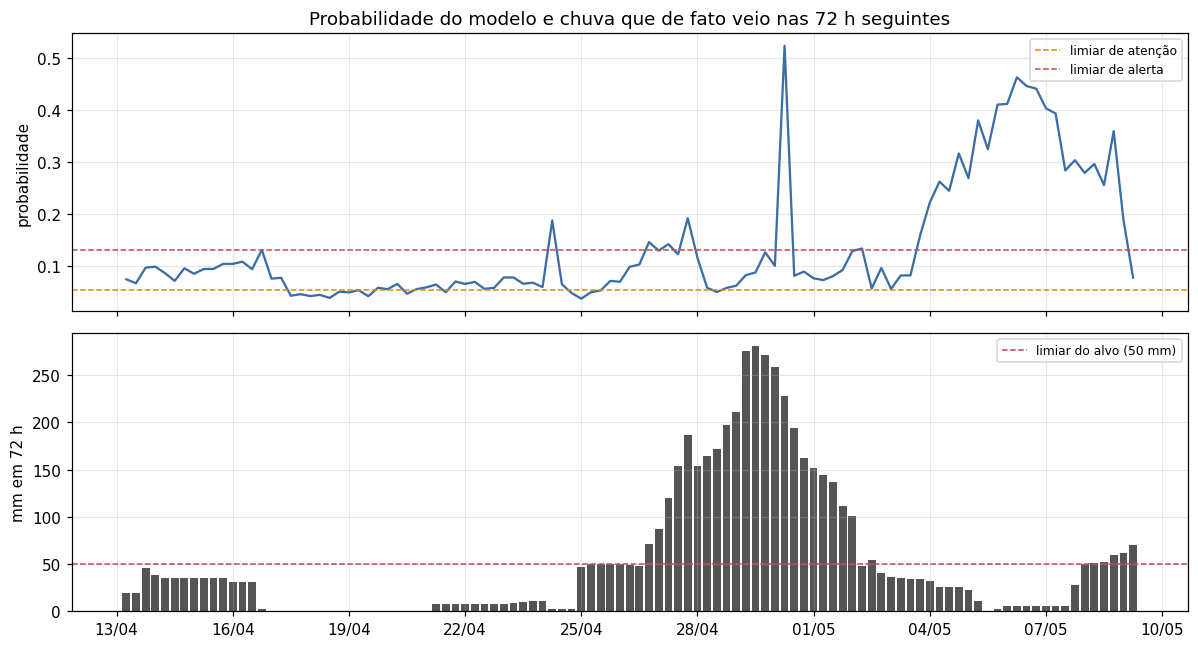

In [ ]:
# o maior episódio do teste, em linha do tempo
import matplotlib.dates as mdates
centro = eps.sort_values("pico de chuva em 72 h (mm)", ascending=False).iloc[0]["início"]
jan = slice(centro - pd.Timedelta(days=12), centro + pd.Timedelta(days=14))
fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [1, 1]})
axs[0].plot(prob.loc[jan].index, prob.loc[jan].values, color="#3b6ea5")
axs[0].axhline(LIM_ATENCAO, color="#d98e04", ls="--", lw=1, label="limiar de atenção")
axs[0].axhline(LIM_ALERTA, color="#c0504d", ls="--", lw=1, label="limiar de alerta")
axs[0].set_ylabel("probabilidade"); axs[0].legend(fontsize=8)
axs[0].set_title("Probabilidade do modelo e chuva que de fato veio nas 72 h seguintes")
axs[1].bar(chuva72.loc[jan].index, chuva72.loc[jan].values, width=0.2, color="#555")
axs[1].axhline(LIMIAR_MM, color="#c0504d", ls="--", lw=1, label=f"limiar do alvo ({LIMIAR_MM} mm)")
axs[1].set_ylabel("mm em 72 h"); axs[1].legend(fontsize=8)
axs[1].xaxis.set_major_locator(mdates.DayLocator(interval=3))
axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
plt.tight_layout(); plt.show()

### Leitura dos exemplos

Nas 24 horas até o início de cada um dos 29 episódios do teste, o modelo chegou a alerta em 5, ficou em atenção em 17 e em baixo em 7. Isso dá alerta antes de 17% dos episódios e atenção ou mais antes de 76%, e o segundo número vale pouco porque a atenção cobre quase metade das linhas.

Na linha do tempo do maior episódio (abril de 2024, 280 mm em 72 h), a probabilidade passa as duas semanas anteriores quase sempre entre 0,04 e 0,13, com um salto isolado a 0,19 em 24/04 às 6 h, 24 horas antes do início, e outro a 0,52 em 30/04 às 6 h. Esse segundo salto vem de uma hora com 25,8 mm de chuva, valor muito além do que o treino viu e que o modelo linear extrapola sem limite. De 4 a 8 de maio, com a chuva já encerrada, a probabilidade fica entre 0,22 e 0,46. Uma nova chuva forte começa em 8 e 9 de maio, mas pelo alvo de 72 h quase todas essas linhas contam como erro. O modelo parece responder mais ao que já choveu (a janela de 168 h tem coeficiente positivo) do que ao que vem.

A tabela de exemplos mostra um acerto (15/06/2025, alerta, 53,8 mm), dois inícios de episódio que o modelo só enxergou nas horas anteriores ou nem isso (em 25/04/2024 chegou a 0,19 um dia antes do início, em 08/06/2023 não passou de 0,06), o pior alarme falso (30/03/2023, probabilidade 0,46 e 1,8 mm de chuva real) e um momento tranquilo (04/07/2025, baixo, 0,2 mm).

## 17. Benefício, limitações e evoluções futuras

O modelo não diz quando a água vai entrar em casa. Ele dá contexto ao morador: nas faixas de atenção e alerta, a época do ano, a pressão e a temperatura se parecem com as de dias que antecederam chuva forte, e vale olhar com mais cuidado o nó e o aviso oficial. Quem decide o aviso imediato continua sendo o nível medido pelo nó, que não depende deste modelo. A Defesa Civil poderia usar as faixas para decidir quando reforçar a atenção, mas isso não foi testado com ela. A faixa baixa nunca deve ser apresentada como "sem risco": 24% das linhas com evento no teste caíram nela.

Limitações desta versão:

- O ganho sobre o acaso é modesto (PR-AUC de teste 0,20 contra 0,083) e boa parte dele é climatologia (seção 13).
- A antecedência é pequena: alerta em 5 dos 29 episódios nas 24 h até o início.
- Há muito aviso falso. Com 70% de recall, atenção e alerta juntos cobrem quase metade das linhas.
- O modelo reage à chuva que já caiu, mais do que à que vem.
- Valores extremos de entrada são extrapolados sem limite, como no salto de 30/04.
- Há uma estação só (A801), e o teste tem 29 episódios independentes. Os intervalos de confiança da seção 11 são largos.
- O alvo (chuva acumulada em 72 h) aproxima o risco de alagamento e não o mede.
- Pressão e vento vêm da estação do INMET. O nó mede nível, chuva, temperatura e umidade. Para o modelo rodar com o que o nó mede, seria preciso buscar pressão e vento na estação oficial ou treinar de novo só com as variáveis do nó. Nenhuma das duas coisas está implementada.

Evoluções futuras, nenhuma delas implementada: limitar (winsorizar) as entradas extremas; usar previsão numérica de tempo como atributo, que é o que de fato traz antecedência; calibrar as probabilidades; incluir mais estações e anos; medir a antecedência de forma explícita; ligar o modelo à API ou à Lambda.

## Resumo da modelagem

- Baselines: sem informação e persistência de 72 h.
- Modelos: regressão logística, Random Forest e Gradient Boosting, com tuning por `GridSearchCV` e `RandomizedSearchCV` sobre `TimeSeriesSplit` com `gap` e nota por PR-AUC.
- No teste, PR-AUC entre 0,18 e 0,20 contra 0,083 do acaso, sem separação clara entre os três.
- Modelo final: regressão logística ajustada. Empata em nota com os outros, é a mais simples, a mais legível e a de probabilidades mais próximas da frequência observada.
- O que ela usa: estação do ano, pressão e temperatura. A chuva acumulada contribui pouco, e boa parte do ganho sobre o acaso é climatologia.
- Faixas: baixo, atenção (70% de recall na validação) e alerta (precisão de 15% na validação). O alerta apareceu em ao menos uma linha de 16 dos 29 episódios do teste, e em 5 deles nas 24 h até o início.
- Limitações e evoluções futuras na seção 17.